# NutriScan CO · Modelos

Resultados de `python -m nutriscan.modelos` (clasificación NOVA 4 frente al resto, a partir
del texto de ingredientes) y de `python -m nutriscan.segmentacion` (K-means). Este cuaderno
solo **lee y grafica** los resultados guardados en `reports/`; no reentrena.

**Diseño de la evaluación (según la retroalimentación del anteproyecto):**
- *Línea base*: predice siempre la clase más frecuente.
- *Global*: 15 % de productos del mundo que el modelo nunca vio.
- *Colombia*: **todos** los productos colombianos, excluidos del entrenamiento.
- *Ruido*: los mismos conjuntos con ingredientes dañados (errores de letras al 10–50 % de
  las palabras, o la lista cortada a la mitad), como haría un OCR imperfecto.

Se reportan F1 de la clase NOVA 4 y **F1 macro** (promedio de ambas clases), porque con
clases desbalanceadas la línea base obtiene un F1 alto sin aprender nada.

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REP = RAIZ / "reports"; FIG = REP / "figuras"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11})
def guardar(fig, nombre):
    fig.tight_layout(); fig.savefig(FIG / f"{nombre}.png", bbox_inches="tight"); plt.show()
COLOR = {"linea_base": "#9A9A9A", "regresion_logistica": "#3B6EA8", "red_neuronal": "#C8102E"}
NOMBRE = {"linea_base": "Línea base", "regresion_logistica": "TF-IDF + Reg. logística", "red_neuronal": "TF-IDF + Red neuronal (MLP)"}
met = pd.read_csv(REP / "modelos" / "metricas.csv")
resumen = json.loads((REP / "modelos" / "resumen.json").read_text())
resumen

{'tamaños': {'entrenamiento': 400980,
  'validacion': 168956,
  'prueba': 168935,
  'colombia': 1560},
 'variables_tfidf': 5000,
 'proporcion_nova4_entrenamiento': 0.6685,
 'clase_mayoritaria': 1,
 'segundos_entrenamiento': {'regresion_logistica': 22.4,
  'red_neuronal': 909.0},
 'capas_red': [1000, 64, 2],
 'entrenamiento_red': 199529,
 'segundos_total': 1082.7}

## 1. Resultados con texto limpio: validación, prueba global y Colombia

In [2]:
limpio = met[met.conjunto.isin(["validacion", "global", "colombia"])]
tabla = limpio.pivot_table(index=["conjunto", "modelo"], values=["precision", "recall", "f1", "f1_macro", "exactitud", "n"], sort=False)
tabla[["n", "precision", "recall", "f1", "f1_macro", "exactitud"]].style.format(
    {"n": "{:,.0f}", "precision": "{:.3f}", "recall": "{:.3f}", "f1": "{:.3f}", "f1_macro": "{:.3f}", "exactitud": "{:.3f}"})

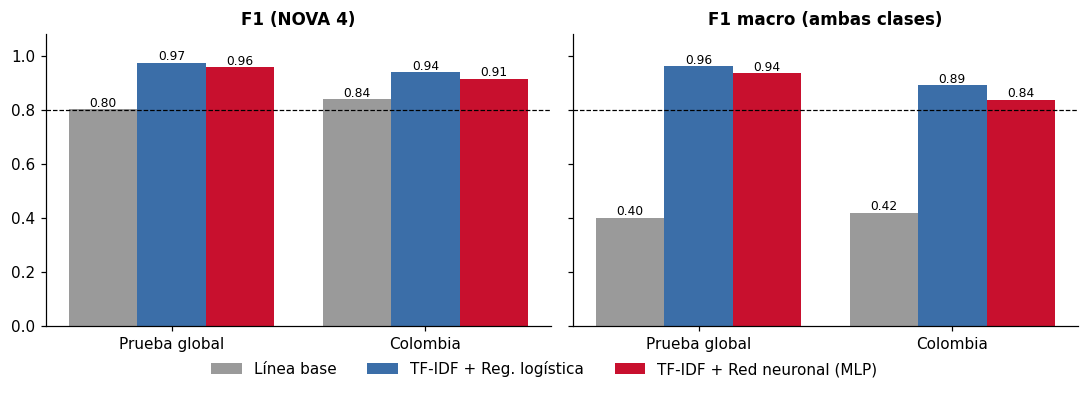

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, metrica in zip(axes, ["f1", "f1_macro"]):
    for i, m in enumerate(NOMBRE):
        d = limpio[limpio.modelo == m].set_index("conjunto").loc[["global", "colombia"]]
        x = [j + (i - 1) * 0.27 for j in range(2)]
        ax.bar(x, d[metrica], 0.27, color=COLOR[m], label=NOMBRE[m])
        for xx, v in zip(x, d[metrica]): ax.text(xx, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
    ax.set_xticks([0, 1], ["Prueba global", "Colombia"]); ax.set_ylim(0, 1.08)
    ax.axhline(0.8, ls="--", lw=0.8, color="black"); ax.set_title("F1 (NOVA 4)" if metrica == "f1" else "F1 macro (ambas clases)")
fig.legend(*axes[0].get_legend_handles_labels(), ncol=3, frameon=False, loc="lower center", bbox_to_anchor=(0.5, -0.06))
guardar(fig, "10_modelos_limpio")

**Interpretación.** La línea base, que siempre responde "ultraprocesado", ya alcanza **F1 = 0,80** en la prueba global porque el 67 % de los productos son NOVA 4. Esto confirma la observación de la docente: la meta del anteproyecto (F1 ≥ 0,80) no era informativa. Por eso se adopta el **F1 macro** (promedio de las dos clases), en el que la línea base obtiene solo 0,40. La regresión logística logra un F1 macro de **0,960** en la prueba global (168.935 productos) y de **0,891 en Colombia** (1.560 productos que nunca se usaron para entrenar): generaliza al mercado colombiano, aunque pierde unos 7 puntos. La red neuronal queda por debajo (0,935 y 0,837) porque, por límite de memoria, usa 1.000 variables en vez de 5.000 y la mitad de los datos de entrenamiento; con este tamaño de datos, un modelo lineal sobre TF-IDF es difícil de superar.

## 2. Matrices de confusión (red neuronal y regresión logística)

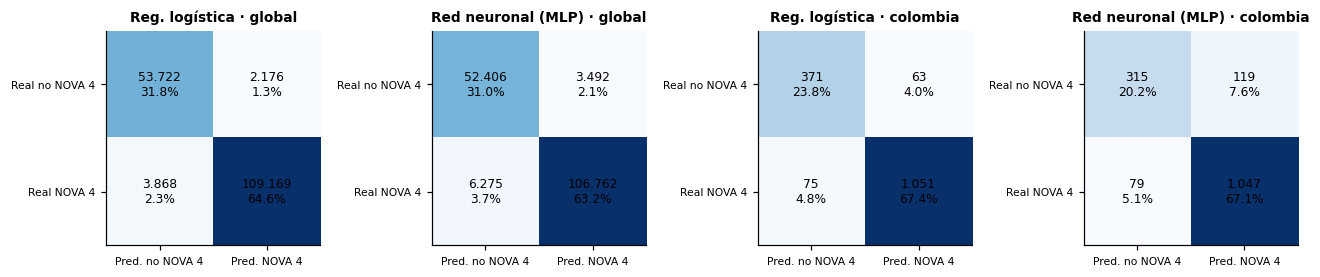

In [4]:
mat = json.loads((REP / "modelos" / "matrices.json").read_text())
fig, axes = plt.subplots(1, 4, figsize=(12, 2.9))
for ax, clave in zip(axes, ["regresion_logistica|global", "red_neuronal|global", "regresion_logistica|colombia", "red_neuronal|colombia"]):
    m = mat[clave]; total = sum(sum(f) for f in m)
    ax.imshow(m, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{m[i][j]:,}\n{m[i][j]/total*100:.1f}%".replace(",", "."), ha="center", va="center", fontsize=8)
    ax.set_xticks([0, 1], ["Pred. no NOVA 4", "Pred. NOVA 4"], fontsize=7)
    ax.set_yticks([0, 1], ["Real no NOVA 4", "Real NOVA 4"], fontsize=7)
    modelo, conj = clave.split("|"); ax.set_title(f"{NOMBRE[modelo].split('+ ')[-1]} · {conj}", fontsize=9)
guardar(fig, "11_matrices_confusion")

**Interpretación.** En la prueba global el error más común son ultraprocesados no detectados (3.868 productos, 2,3 %). En Colombia aumentan los **falsos positivos**: 63 productos (4,0 %) con la regresión y 119 (7,6 %) con la red neuronal, es decir, productos no ultraprocesados que el modelo marca como NOVA 4. Una hipótesis es que hay muchos menos ejemplos de entrenamiento en español que en francés o inglés.

## 3. Prueba de robustez: ingredientes con errores (el aporte real del modelo)

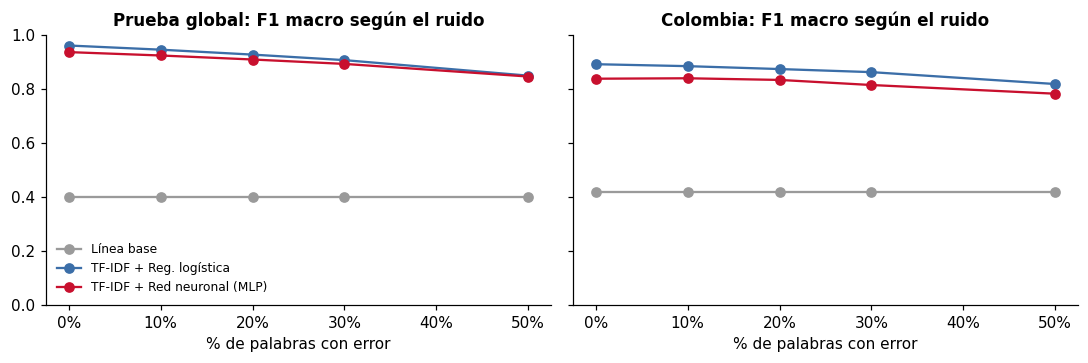

nivel                            0      10     20     30     50
conjunto modelo                                                
global   linea_base           0.401  0.401  0.401  0.401  0.401
         regresion_logistica  0.960  0.944  0.926  0.906  0.849
         red_neuronal         0.936  0.923  0.908  0.892  0.845
colombia linea_base           0.419  0.419  0.419  0.419  0.419
         regresion_logistica  0.891  0.884  0.873  0.862  0.818
         red_neuronal         0.837  0.839  0.833  0.814  0.782

In [5]:
filas = []
for _, r in met.iterrows():
    c = r.conjunto
    for base in ["global", "colombia"]:
        if c == base: filas.append((base, 0, r.modelo, r.f1_macro, r.f1))
        elif c.startswith(base + "_errores_"): filas.append((base, int(c.split("_")[-1]), r.modelo, r.f1_macro, r.f1))
ruido = pd.DataFrame(filas, columns=["conjunto", "nivel", "modelo", "f1_macro", "f1"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, base in zip(axes, ["global", "colombia"]):
    for m in NOMBRE:
        d = ruido[(ruido.conjunto == base) & (ruido.modelo == m)].sort_values("nivel")
        ax.plot(d.nivel, d.f1_macro, marker="o", color=COLOR[m], label=NOMBRE[m])
    ax.set_title(f"{'Prueba global' if base == 'global' else 'Colombia'}: F1 macro según el ruido")
    ax.set_xlabel("% de palabras con error"); ax.set_ylim(0, 1)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter())
axes[0].legend(fontsize=8, frameon=False)
guardar(fig, "12_robustez_ruido")
ruido.pivot_table(index=["conjunto", "modelo"], columns="nivel", values="f1_macro", sort=False).round(3)

In [6]:
trunc = met[met.conjunto.str.contains("truncado") | met.conjunto.isin(["global", "colombia"])]
trunc.pivot_table(index="modelo", columns="conjunto", values="f1_macro").round(3)

conjunto,colombia,colombia_truncado_50,global,global_truncado_50
modelo,,,,
linea_base,0.419,0.419,0.401,0.401
red_neuronal,0.837,0.778,0.936,0.757
regresion_logistica,0.891,0.782,0.960,0.764


**Interpretación.** Con errores de letras, ambos modelos se degradan de forma **gradual**: con el 30 % de las palabras dañadas, la regresión aún tiene F1 macro de 0,906 (global) y 0,862 (Colombia); con el 50 %, 0,849 y 0,818. En cambio, **cortar la lista a la mitad es mucho más dañino** (0,764 global): la precisión se mantiene (0,99), pero el recall cae de 0,97 a 0,66, porque los aditivos y aromas que delatan el ultraprocesamiento suelen ir al final de la lista. Este es el hallazgo principal de la evaluación: el modelo tolera errores de escritura (como los de un OCR), pero necesita la lista completa. Queda pendiente comparar con las reglas exactas de NOVA aplicadas al mismo texto con ruido.

## 4. ¿Qué aprendió el modelo? Términos más influyentes (regresión logística)

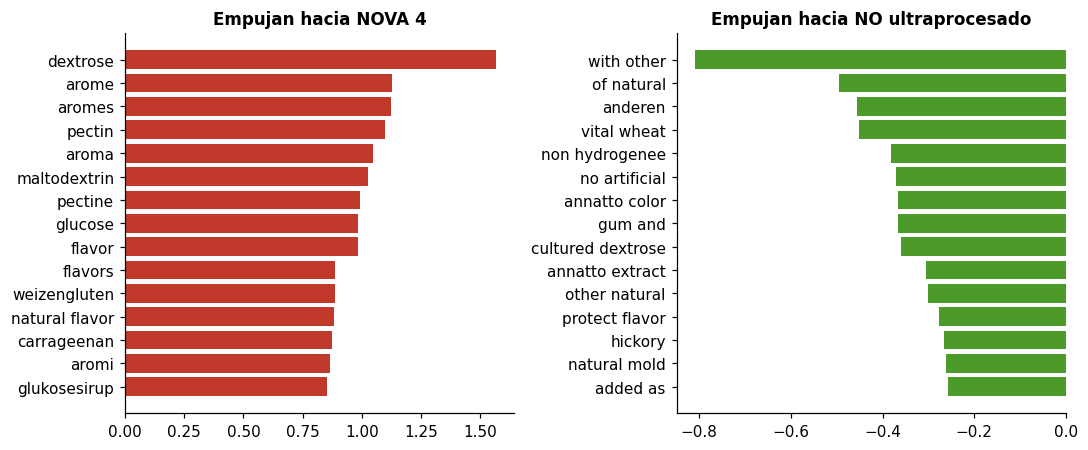

In [7]:
pal = pd.read_csv(REP / "modelos" / "palabras_clave.csv")
# Solo términos en alfabeto latino (la fuente de las gráficas no tiene caracteres chinos, etc.)
pal = pal[pal.termino.map(lambda t: all(ord(c) < 0x250 for c in t))]
neg, pos = pal.head(15), pal.tail(15).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
axes[0].barh(pos.termino[::-1], pos.coeficiente[::-1], color="#C0392B"); axes[0].set_title("Empujan hacia NOVA 4")
axes[1].barh(neg.termino[::-1], neg.coeficiente[::-1], color="#4C9A2A"); axes[1].set_title("Empujan hacia NO ultraprocesado")
guardar(fig, "13_terminos_influyentes")

**Interpretación.** Los términos que más empujan hacia NOVA 4 son justamente los "marcadores" de ultraprocesamiento que usa la clasificación NOVA: dextrosa, aromas (en varios idiomas: arome, aroma, flavor), maltodextrina, pectina, glucosa, carragenina y gluten. Es decir, **el modelo aprende en buena parte las reglas de NOVA**, como advirtió la docente. Los términos que empujan hacia "no ultraprocesado" son menos interpretables ("with other", "anderen", "no artificial") y sugieren que el modelo también aprende rasgos de redacción de ciertas etiquetas (p. ej. estadounidenses). Para la entrega final se entrenará un modelo sin los términos-marcador, para medir cuánto depende de ellos.

## 5. Segmentación con K-means

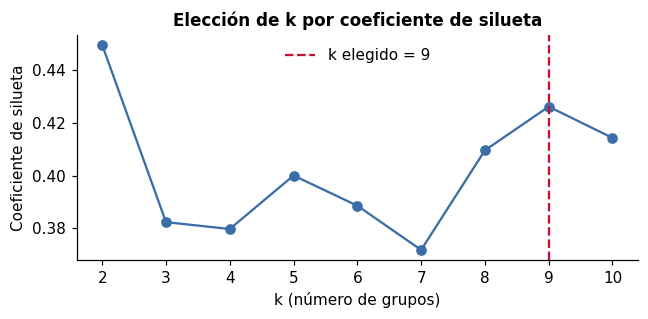

{'productos_con_perfil_completo': 2730572,
 'productos_usados': 503573,
 'mejor_k': 9,
 'silueta_mejor_k': 0.426,
 'segundos': 180.1}

In [8]:
sil = pd.read_csv(REP / "segmentacion" / "silueta.csv")
seg = json.loads((REP / "segmentacion" / "resumen.json").read_text())
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(sil.k, sil.silueta, marker="o", color="#3B6EA8")
ax.axvline(seg["mejor_k"], ls="--", color="#C8102E", label=f"k elegido = {seg['mejor_k']}")
ax.set_xlabel("k (número de grupos)"); ax.set_ylabel("Coeficiente de silueta"); ax.legend(frameon=False)
ax.set_title("Elección de k por coeficiente de silueta")
guardar(fig, "14_silueta")
seg

In [9]:
perf = pd.read_csv(REP / "segmentacion" / "perfiles.csv")
co = pd.read_csv(REP / "segmentacion" / "colombia_por_grupo.csv").rename(columns={"count": "productos_colombia"})
perf = perf.merge(co, on="grupo", how="left").fillna({"productos_colombia": 0})
perf["pct_colombia"] = (perf.productos_colombia / perf.productos_colombia.sum() * 100).round(1)
# Nombres asignados al revisar las medianas de cada grupo (semilla fija: los números no cambian)
NOMBRES = {0: "Carnes, pescados y proteicos", 1: "Panes, harinas y pastas", 2: "Bebidas y frutas con azúcar",
           3: "Quesos y embutidos grasos", 4: "Bebidas sin calorías y aguas", 5: "Galletas, chocolates y snacks dulces",
           6: "Dulces y azucarados sin grasa", 7: "Aceites y grasas", 8: "Lácteos líquidos, salsas y preparados"}
perf.insert(1, "nombre", perf.grupo.map(NOMBRES))
perf.to_csv(REP / "segmentacion" / "perfiles_con_nombre.csv", index=False)
perf

,grupo,nombre,productos,energia_kcal,fat_100g,saturated_fat_100g,carbohydrates_100g,sugars_100g,proteins_100g,sodio_mg_100g,pct_nova4,pct_con_sellos,productos_colombia,pct_colombia
0,0,"Carnes, pescados y proteicos",50101,139.0,5.0,1.4,0.9,0.4,20.0,400.0,57.0,82.0,247,6.3
1,1,"Panes, harinas y pastas",109072,283.2,7.6,1.6,39.0,2.7,9.0,440.0,69.2,84.4,940,24.1
2,2,Bebidas y frutas con azúcar,41597,55.0,0.1,0.0,12.0,5.7,0.5,0.0,42.6,52.3,270,6.9
3,3,Quesos y embutidos grasos,65920,325.0,26.0,10.1,1.9,0.5,18.1,669.0,54.6,97.3,356,9.1
4,4,Bebidas sin calorías y aguas,16846,1.0,0.0,0.0,0.0,0.0,0.0,0.0,59.5,45.2,164,4.2
5,5,"Galletas, chocolates y snacks dulces",103549,458.6,22.0,9.0,52.0,27.5,6.3,140.0,85.5,96.6,878,22.5
6,6,Dulces y azucarados sin grasa,33392,321.7,0.1,0.0,75.0,55.0,0.6,20.0,71.5,91.4,231,5.9
7,7,Aceites y grasas,15543,689.0,71.0,13.0,0.6,0.0,0.3,0.0,28.3,83.5,121,3.1
8,8,"Lácteos líquidos, salsas y preparados",67553,67.0,1.4,0.3,7.7,3.6,2.4,190.9,58.8,90.7,694,17.8


**Interpretación.** La silueta es máxima con k = 2 (0,449), pero esa partición solo separa productos livianos de densos. Entre k ≥ 3 el mejor es **k = 9 (silueta 0,426)**, con grupos de perfil reconocible (medianas por 100 g). Los grupos con más ultraprocesados son "galletas, chocolates y snacks dulces" (85,5 % NOVA 4, 459 kcal, 27,5 g de azúcar) y "dulces y azucarados sin grasa" (71,5 %). Los 3.901 productos colombianos con perfil completo se concentran en panes y harinas (24 %), galletas y snacks dulces (23 %) y lácteos líquidos y salsas (18 %).

## Conclusiones de los modelos

1. La meta F1 ≥ 0,80 se reemplaza por **F1 macro**, porque la línea base ya alcanza F1 = 0,80 sin aprender nada.
2. La regresión logística sobre TF-IDF es el mejor modelo: F1 macro de 0,960 (global) y 0,891 (Colombia). La red neuronal (MLP) no la supera.
3. El modelo es robusto a errores de letras (0,82 en Colombia con la mitad de las palabras dañadas), pero no a listas incompletas (el recall cae al 66 %).
4. El modelo aprende en gran parte los mismos marcadores que usa NOVA. Su valor está en tolerar texto con errores, no en reemplazar las reglas cuando el texto está limpio.
5. K-means encuentra 9 perfiles nutricionales interpretables; Colombia se concentra en panes, snacks dulces y lácteos.